# Guía 10 — Optimización de modelos e hiperparámetros
**GridSearchCV, validación cruzada y selección reproducible**

**Proyecto**: EdTech Learning Analytics — Proyecto Final

**Módulo**: Gestión de Datos para Inteligencia Artificial y Big Data (COIDS1604)

**Grupo**: 1

**Integrante a cargo**: Isela Alexandra Quintanilla Cruz (carnet 088525)

---

## Pregunta predictiva heredada (Guías 8 y 9)

> **¿Qué nivel de `riesgo_academico` (Bajo, Medio o Alto) tendrá un estudiante en la materia del ciclo actual, a partir de su desempeño, asistencia, tareas, participación en el LMS y contexto socioeconómico?**

- **Tipo de problema:** clasificación multiclase ordinal (Bajo < Medio < Alto). Por eso la guía se adapta a la *variante para clasificación* (sección XII): las métricas MAE/RMSE/R² del caso DataRetail AI se sustituyen por **F1 macro** (métrica principal, la misma de la Guía 9), accuracy, recall de la clase Alto y error ordinal.
- **Modelo candidato de la Guía 9:** Regresión logística (F1 macro CV 0.505 ± 0.088; prueba 0.584).
- **Validación:** los datos son registros independientes por estudiante-materia, no una serie temporal, por lo que se mantiene `StratifiedKFold` (mismos folds de la Guía 9) en lugar de `TimeSeriesSplit`.
- **Objetivo de esta guía:** comprobar, buscando de forma sistemática y **sin tocar el conjunto de prueba**, si alguna configuración de hiperparámetros mejora de verdad la generalización del candidato, y decidir con evidencia si vale la pena adoptarla.

### Protocolo declarado *antes* de ver resultados
Para que la decisión no dependa de la cifra que salga, las reglas se fijan aquí:

1. **Métrica principal:** F1 macro en validación cruzada (no se cambia después).
2. **Selección:** se aplica la *regla de un error estándar*: entre todas las configuraciones cuyo F1 CV esté a menos de 1 error estándar de la mejor, se elige la **más regularizada** (menor `C`). Razón: en la Guía 9 las diferencias entre modelos fueron menores que la desviación entre folds, así que la configuración más simple es la más defendible.
3. **Adopción:** el modelo optimizado reemplaza a la configuración de la Guía 9 solo si (a) mejora el F1 CV en al menos **0.01**, (b) el recall de Alto en CV no cae más de **0.03** y (c) la desviación entre folds no empeora más de un 25 %.
4. **Prueba final:** se evalúa **una sola vez**, al cerrar la selección. El código lo impone (una segunda llamada lanza error).

In [25]:
# ============================================================
# CELDA 1: Importaciones, configuración y referencias de la Guía 9
# ============================================================
import sys
import json
import time
import hashlib
import platform
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import spearmanr

import sklearn
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, make_scorer,
                             precision_score, recall_score, classification_report)
from sklearn.model_selection import (GridSearchCV, ParameterGrid, StratifiedKFold,
                                     cross_val_score, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --- Configuración global -------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

NOMBRE_DATASET = "dataset_limpio_Proyecto_EdTech_Learning_Analytics.csv"
ORDEN_CLASES = ["Bajo", "Medio", "Alto"]
MAPA_ORD = {c: i for i, c in enumerate(ORDEN_CLASES)}
N_FOLDS = 5          # igual que la Guía 9 (mismos folds)
N_BOOT = 2000        # remuestreos bootstrap para intervalos en prueba
RUN_NESTED = True    # validación cruzada anidada (más lenta, más honesta)

# --- Reglas de decisión declaradas de antemano ----------------------------
UMBRAL_MEJORA_F1_CV = 0.01
MAX_CAIDA_RECALL_ALTO = 0.03
MAX_AUMENTO_STD = 0.25

# --- Referencias de la Guía 9 (para verificar continuidad) ----------------
G9_SHA_DATASET = "26970d067b33"
G9_HUELLA_TEST = "a82784986b90"
G9_F1_CV, G9_F1_CV_STD = 0.505, 0.088
G9_F1_TEST, G9_ACC_TEST = 0.584, 0.6067

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 11
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FECHA_EJEC = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print("Entorno registrado")
print(f"  Python: {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"  Fecha de ejecución: {FECHA_EJEC} | Semilla: {RANDOM_STATE}")

Entorno registrado
  Python: 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1
  Fecha de ejecución: 2026-11-18 08:55:11 | Semilla: 42


In [26]:
# ============================================================
# CELDA 2: Localizar y cargar el dataset (mismo de la Guía 9)
# ============================================================
def en_colab():
    return "google.colab" in sys.modules

def localizar_dataset(nombre):
    candidatos = [
        Path("datos/procesados") / nombre,
        Path("../datos/procesados") / nombre,
        Path("proyecto_datos_ia/datos/procesados") / nombre,
        Path("/content/datos/procesados") / nombre,
        Path("/content/proyecto_datos_ia/datos/procesados") / nombre,
        Path("/content") / nombre,
        Path(nombre),
    ]
    for c in candidatos:
        if c.exists():
            return c.resolve()
    return None

ruta_csv = localizar_dataset(NOMBRE_DATASET)

if ruta_csv is None and en_colab():
    from google.colab import files
    print(f"Sube el archivo: {NOMBRE_DATASET}")
    subido = files.upload()
    destino = Path("/content/proyecto_datos_ia/datos/procesados")
    destino.mkdir(parents=True, exist_ok=True)
    for nombre, contenido in subido.items():
        (destino / nombre).write_bytes(contenido)
    ruta_csv = destino / NOMBRE_DATASET

if ruta_csv is None:
    raise FileNotFoundError(f"No se encontró {NOMBRE_DATASET}. Colócalo en datos/procesados/.")

ROOT = ruta_csv.parent.parent.parent if ruta_csv.parent.name == "procesados" else ruta_csv.parent
DIR_DATOS   = ROOT / "datos" / "procesados"
DIR_DOCS    = ROOT / "documentos"
DIR_MODELOS = ROOT / "modelos"
DIR_EVID    = ROOT / "evidencias" / "guia10_optimizacion"
for d in (DIR_DATOS, DIR_DOCS, DIR_MODELOS, DIR_EVID):
    d.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ruta_csv)
SHA_DATASET = hashlib.sha256(ruta_csv.read_bytes()).hexdigest()[:12]
MISMO_DATASET = (SHA_DATASET == G9_SHA_DATASET)

print(f"Archivo: {ruta_csv.name}")
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"Huella actual: {SHA_DATASET} | Huella Guía 9: {G9_SHA_DATASET} -> "
      f"{'COINCIDE (mismo dataset)' if MISMO_DATASET else 'AVISO: el dataset cambió respecto a la Guía 9'}")
print("\nDistribución de riesgo_academico:")
print(df["riesgo_academico"].value_counts().reindex(ORDEN_CLASES).to_string())

Archivo: dataset_limpio_Proyecto_EdTech_Learning_Analytics.csv
Dimensiones: 1000 filas x 43 columnas
Huella actual: 26970d067b33 | Huella Guía 9: 26970d067b33 -> COINCIDE (mismo dataset)

Distribución de riesgo_academico:
riesgo_academico
Bajo     211
Medio    322
Alto     467


In [27]:
# ============================================================
# CELDA 3: Variables X e y (idénticas a la Guía 9; no se modifican)
# ============================================================
features_base = [
    "edad", "anio_ingreso", "ciclo_actual", "horas_trabajo_semana",
    "faltas_consecutivas", "tareas_entregadas", "tareas_tarde",
    "porcentaje_asistencia", "actividad_lms", "total_observaciones",
    "semana_evaluacion",
    "sexo", "facultad", "carrera", "turno", "municipio_residencia",
    "zona", "acceso_internet_casa", "beca", "materia", "participacion_nivel",
    "trabaja", "requiere_seguimiento", "es_fin_semana",
]
features_notas = ["nota_teoria", "nota_laboratorio", "nota_final",
                  "promedio_academico", "materia_reprobada"]
features = features_base + features_notas

faltantes = [f for f in features + ["riesgo_academico"] if f not in df.columns]
assert not faltantes, f"Columnas no encontradas: {faltantes}"

X = df[features]
y = df["riesgo_academico"]
print(f"Variables predictoras: {len(features)} | Objetivo: riesgo_academico | X: {X.shape}")

# Verificación de estructura por estudiante (alerta heredada de la Guía 9):
# si un mismo estudiante aparece en varias filas, un split por fila puede filtrar información.
posibles_id = [c for c in ["carnet", "id_estudiante", "codigo_estudiante", "estudiante_id"] if c in df.columns]
if posibles_id:
    col_id = posibles_id[0]
    print(f"\nColumna identificadora detectada: {col_id} | únicos: {df[col_id].nunique()} de {len(df)} filas")
    if df[col_id].nunique() < len(df):
        print("   AVISO: hay estudiantes repetidos. Documentar como limitación y valorar GroupKFold (experimento nuevo).")
else:
    print("\nNo hay columna identificadora en el dataset: no se puede verificar repetición de estudiantes. "
          "Se documenta como limitación.")

Variables predictoras: 29 | Objetivo: riesgo_academico | X: (1000, 29)

Columna identificadora detectada: carnet | únicos: 1000 de 1000 filas


In [28]:
# ============================================================
# CELDA 4: Misma partición 70/15/15 de la Guía 9 y verificación del holdout
# ============================================================
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp)

def huella_indices(idx):
    return hashlib.sha256(",".join(map(str, sorted(idx))).encode()).hexdigest()[:12]

HUELLA_TEST = huella_indices(X_test.index)
MISMO_TEST = (HUELLA_TEST == G9_HUELLA_TEST)

print(f"Entrenamiento: {len(X_train)} | Validación: {len(X_val)} | Prueba final: {len(X_test)}")
print(f"Huella del test: {HUELLA_TEST} | Guía 9: {G9_HUELLA_TEST} -> "
      f"{'COINCIDE: holdout sin cambios' if MISMO_TEST else 'AVISO: el holdout NO coincide con el de la Guía 9'}")

assert len(X_train) + len(X_val) + len(X_test) == len(X)
assert not (set(X_train.index) & set(X_test.index))
assert not (set(X_val.index) & set(X_test.index))
print("Sin solapamiento entre conjuntos.")
print("\nA partir de aquí X_test / y_test NO intervienen en la búsqueda (se usan una sola vez, en la celda de evaluación final).")

Entrenamiento: 700 | Validación: 150 | Prueba final: 150
Huella del test: a82784986b90 | Guía 9: a82784986b90 -> COINCIDE: holdout sin cambios
Sin solapamiento entre conjuntos.

A partir de aquí X_test / y_test NO intervienen en la búsqueda (se usan una sola vez, en la celda de evaluación final).


In [29]:
# ============================================================
# CELDA 5: Pipeline reproducible, métricas y folds (iguales a la Guía 9)
# ============================================================
cols_num = X_train.select_dtypes(include="number").columns.tolist()
cols_cat = X_train.select_dtypes(exclude="number").columns.tolist()

def crear_preprocesador(escalar=True):
    pasos_num = [("imputer", SimpleImputer(strategy="median"))]
    if escalar:
        pasos_num.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(pasos_num), cols_num),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), cols_cat),
    ])

def crear_pipeline(**kw_clf):
    """Preprocesamiento + regresión logística. Todo se ajusta DENTRO de cada fold."""
    params = {"random_state": RANDOM_STATE}
    params.update(kw_clf)
    return Pipeline([("prep", crear_preprocesador(True)),
                     ("clf", LogisticRegression(**params))])

# Configuración de la Guía 9 (referencia "antes")
def crear_config_g9():
    return crear_pipeline(C=1, max_iter=2000, class_weight="balanced")

# --- Métricas -------------------------------------------------------------
def recall_alto(y_real, y_pred):
    return recall_score(y_real, y_pred, labels=["Alto"], average=None, zero_division=0)[0]

def mae_ordinal(y_real, y_pred):
    r = pd.Series(np.asarray(y_real)).map(MAPA_ORD).to_numpy()
    p = pd.Series(np.asarray(y_pred)).map(MAPA_ORD).to_numpy()
    return float(np.abs(r - p).mean())

SCORING = {
    "f1_macro": "f1_macro",                                   # métrica principal (selección)
    "accuracy": "accuracy",
    "recall_alto": make_scorer(recall_alto),
    "mae_ordinal": make_scorer(mae_ordinal, greater_is_better=False),  # secundaria (distancia entre clases)
}

# Mismos folds que la Guía 9
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
print("Pipeline, métricas y folds definidos.")
print(f"Columnas numéricas: {len(cols_num)} | categóricas/booleanas: {len(cols_cat)}")

Pipeline, métricas y folds definidos.
Columnas numéricas: 16 | categóricas/booleanas: 13


## Parte B — Referencia "antes" (solo sobre entrenamiento)
Se recalculan en validación cruzada el baseline y la configuración de la Guía 9 con **los mismos folds**. Así la comparación antes/después es limpia y se verifica la continuidad con la guía anterior sin tocar la prueba.

In [30]:
# ============================================================
# CELDA 6: Referencia en validación cruzada (baseline y configuración Guía 9)
# ============================================================
def resumir_cv(nombre, estimador):
    r = cross_validate(clone(estimador), X_train, y_train, cv=cv, scoring=SCORING,
                       return_train_score=True, n_jobs=-1)
    return {
        "Modelo": nombre,
        "F1_cv": r["test_f1_macro"].mean(), "F1_std": r["test_f1_macro"].std(ddof=1),
        "F1_train": r["train_f1_macro"].mean(),
        "Acc_cv": r["test_accuracy"].mean(),
        "RecallAlto_cv": r["test_recall_alto"].mean(),
        "MAEord_cv": -r["test_mae_ordinal"].mean(),
        "t_fit_s": r["fit_time"].mean(),
    }, r["test_f1_macro"]

fila_base, folds_base = resumir_cv("Baseline", DummyClassifier(strategy="most_frequent"))
fila_g9, folds_g9 = resumir_cv("Candidato Guía 9", crear_config_g9())
df_ref = pd.DataFrame([fila_base, fila_g9]).set_index("Modelo")

print("REFERENCIA EN VALIDACIÓN CRUZADA (solo X_train)")
print("=" * 90)
display(df_ref.round(3))

cont_cv = (abs(fila_g9["F1_cv"] - G9_F1_CV) < 2e-3) and (abs(fila_g9["F1_std"] - G9_F1_CV_STD) < 2e-3)
print(f"\nContinuidad con Guía 9 (F1 CV {G9_F1_CV} ± {G9_F1_CV_STD}): "
      f"{'VERIFICADA' if cont_cv else 'AVISO: no coincide; revisar dataset, split o versión de librerías'}")
print("F1 por fold (Guía 9):", np.round(folds_g9, 3))

REFERENCIA EN VALIDACIÓN CRUZADA (solo X_train)


,F1_cv,F1_std,F1_train,Acc_cv,RecallAlto_cv,MAEord_cv,t_fit_s
Modelo,,,,,,,
Baseline,0.212,0.001,0.212,0.467,1.000,0.744,0.003
Candidato Guía 9,0.505,0.088,0.673,0.520,0.532,0.597,0.083



Continuidad con Guía 9 (F1 CV 0.505 ± 0.088): VERIFICADA
F1 por fold (Guía 9): [0.583 0.409 0.488 0.436 0.608]


## Parte C — Espacio de búsqueda
Se optimiza **solo la familia seleccionada** (regresión logística). Cada rango tiene una hipótesis técnica; no se amplía sin justificar el costo.

| Hiperparámetro | Valores | Justificación |
|---|---|---|
| `C` | 0.01, 0.03, 0.1, 0.3, 1, 3, 10 | Inverso de la regularización. Con 29 variables y ~100 columnas tras one-hot (muchas con pocas filas, como `carrera` y `municipio_residencia`), más regularización suele reducir la varianza que se vio entre folds (std 0.088). Escala logarítmica; el valor 1 es el de la Guía 9. |
| `penalty` | `l2`, `l1` | `l2` encoge todos los coeficientes (Guía 9). `l1` puede anular los de categorías irrelevantes: sirve para depurar el exceso de columnas one-hot. No se incluye *elastic net* para no ampliar el grid sin hipótesis. |
| `class_weight` | `None`, `balanced` | La Guía 9 usó `balanced`. Se prueba si compensar clases ayuda o si solo desplaza errores (la clase Alto es la mayoritaria, 46.7 %). |
| `solver` | `lbfgs` (con `l2`), `saga` (con `l1`) | Cada penalización necesita su solver. Se declaran en listas de diccionarios para no generar combinaciones inválidas. |

Sin buscar: `max_iter` (se fija en 5000 y se verifica convergencia después) y el preprocesamiento (no cambia).

In [31]:
# ============================================================
# CELDA 7: Definir el grid y estimar el costo
# ============================================================
C_VALORES = [0.01, 0.03, 0.1, 0.3, 1, 3, 10]
CLASS_WEIGHT = [None, "balanced"]

param_grid = [
    {"clf__solver": ["lbfgs"], "clf__penalty": ["l2"], "clf__C": C_VALORES, "clf__class_weight": CLASS_WEIGHT},
    {"clf__solver": ["saga"],  "clf__penalty": ["l1"], "clf__C": C_VALORES, "clf__class_weight": CLASS_WEIGHT},
]

n_comb = len(ParameterGrid(param_grid))
print("ESPACIO DE BÚSQUEDA")
print("=" * 70)
print(f"Combinaciones: {n_comb}  (2 penalizaciones x {len(C_VALORES)} valores de C x {len(CLASS_WEIGHT)} class_weight)")
print(f"Entrenamientos: {n_comb} x {N_FOLDS} folds = {n_comb * N_FOLDS}, más 1 refit final")
print("La configuración de la Guía 9 (C=1, l2, balanced, lbfgs) está incluida en el grid.")

ESPACIO DE BÚSQUEDA
Combinaciones: 28  (2 penalizaciones x 7 valores de C x 2 class_weight)
Entrenamientos: 28 x 5 folds = 140, más 1 refit final
La configuración de la Guía 9 (C=1, l2, balanced, lbfgs) está incluida en el grid.


In [32]:
# ============================================================
# CELDA 8: GridSearchCV (solo X_train; métrica principal F1 macro)
# ============================================================
busqueda = GridSearchCV(
    estimator=crear_pipeline(max_iter=5000),
    param_grid=param_grid,
    scoring=SCORING,
    refit="f1_macro",          # el "mejor" se define por F1 macro
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    error_score="raise",
    verbose=1,
)

t0 = time.perf_counter()
busqueda.fit(X_train, y_train)        # <- X_test NO participa
tiempo_busqueda = time.perf_counter() - t0

print(f"\nTiempo total de búsqueda: {tiempo_busqueda:.1f} s")
print(f"Mejor configuración por F1 macro (media): {busqueda.best_params_}")
print(f"F1 macro CV de la mejor: {busqueda.best_score_:.3f}")
print("Nota: el mejor puntaje de un grid es optimista (se eligió entre {} candidatos); ver CV anidada más abajo.".format(n_comb))

n_iter_max = int(np.max(busqueda.best_estimator_.named_steps["clf"].n_iter_))
print(f"Convergencia del mejor modelo: {n_iter_max} iteraciones de 5000 -> "
      f"{'OK' if n_iter_max < 5000 else 'AVISO: no convergió, subir max_iter'}")

Fitting 5 folds for each of 28 candidates, totalling 140 fits

Tiempo total de búsqueda: 155.3 s
Mejor configuración por F1 macro (media): {'clf__C': 0.03, 'clf__class_weight': 'balanced', 'clf__penalty': 'l1', 'clf__solver': 'saga'}
F1 macro CV de la mejor: 0.583
Nota: el mejor puntaje de un grid es optimista (se eligió entre 28 candidatos); ver CV anidada más abajo.
Convergencia del mejor modelo: 660 iteraciones de 5000 -> OK


## Parte D — Análisis de todos los experimentos
No se mira solo el ganador: se revisan media, dispersión, brecha entrenamiento/validación y tiempo de **todas** las configuraciones.

In [33]:
# ============================================================
# CELDA 9: cv_results_ completo como tabla de experimentos
# ============================================================
res = pd.DataFrame(busqueda.cv_results_)
tabla = pd.DataFrame({
    "C": res["param_clf__C"].astype(float),
    "penalty": res["param_clf__penalty"].astype(str),
    "class_weight": res["param_clf__class_weight"].map(lambda v: "balanced" if v == "balanced" else "None"),
    "F1_cv": res["mean_test_f1_macro"],
    "F1_std": res["std_test_f1_macro"],
    "F1_train": res["mean_train_f1_macro"],
    "Acc_cv": res["mean_test_accuracy"],
    "RecallAlto_cv": res["mean_test_recall_alto"],
    "MAEord_cv": -res["mean_test_mae_ordinal"],
    "t_fit_s": res["mean_fit_time"],
    "rank_f1": res["rank_test_f1_macro"],
    "params": res["params"],
})
tabla["Brecha_F1"] = tabla["F1_train"] - tabla["F1_cv"]
tabla["SE"] = tabla["F1_std"] / np.sqrt(N_FOLDS)
tabla = tabla.sort_values("rank_f1").reset_index(drop=True)

cols_show = ["rank_f1", "C", "penalty", "class_weight", "F1_cv", "F1_std", "Brecha_F1",
             "RecallAlto_cv", "MAEord_cv", "t_fit_s"]
print("TOP 10 CONFIGURACIONES (ordenadas por F1 macro CV)")
print("=" * 100)
display(tabla[cols_show].head(10).round(3))

# La configuración de la Guía 9 dentro del grid: debe reproducir la referencia
m_g9 = (tabla["C"] == 1) & (tabla["penalty"] == "l2") & (tabla["class_weight"] == "balanced")
f1_g9_grid = tabla.loc[m_g9, "F1_cv"].iloc[0]
rank_g9 = int(tabla.loc[m_g9, "rank_f1"].iloc[0])
print(f"\nConfiguración Guía 9 dentro del grid: F1 CV {f1_g9_grid:.3f} (ranking {rank_g9} de {n_comb}); "
      f"referencia recalculada: {fila_g9['F1_cv']:.3f}")

# Dispersión global: ¿el grid separa de verdad las configuraciones?
rango = tabla["F1_cv"].max() - tabla["F1_cv"].min()
print(f"Rango de F1 CV entre las {n_comb} configuraciones: {rango:.3f} | "
      f"std típica entre folds: {tabla['F1_std'].median():.3f}")

# Ejercicio 4 (métrica alternativa): ¿el ranking cambia si se mide la distancia ordinal?
rho, _ = spearmanr(tabla["F1_cv"], tabla["MAEord_cv"])
print(f"Correlación de Spearman F1 CV vs error ordinal CV: {rho:.2f} "
      f"({'rankings consistentes' if rho < -0.7 else 'los rankings difieren: la métrica elegida importa'})")

TOP 10 CONFIGURACIONES (ordenadas por F1 macro CV)


,rank_f1,C,penalty,class_weight,F1_cv,F1_std,Brecha_F1,RecallAlto_cv,MAEord_cv,t_fit_s
0,1,0.03,l1,balanced,0.583,0.059,-0.002,0.453,0.513,4.069
1,2,0.01,l1,balanced,0.573,0.051,-0.000,0.453,0.541,0.597
2,3,0.10,l1,balanced,0.573,0.060,0.009,0.453,0.519,4.803
3,4,0.30,l1,balanced,0.560,0.057,0.045,0.462,0.529,6.115
4,5,0.01,l2,balanced,0.553,0.039,0.063,0.492,0.530,0.043
5,6,0.03,l2,balanced,0.548,0.047,0.078,0.480,0.536,0.062
6,7,0.10,l1,None,0.545,0.064,0.016,0.456,0.491,5.349
7,8,0.30,l1,None,0.521,0.069,0.096,0.532,0.549,5.284
8,9,0.10,l2,balanced,0.518,0.060,0.124,0.492,0.571,0.059
9,10,1.00,l1,balanced,0.513,0.073,0.143,0.505,0.589,2.900



Configuración Guía 9 dentro del grid: F1 CV 0.505 (ranking 15 de 28); referencia recalculada: 0.505
Rango de F1 CV entre las 28 configuraciones: 0.371 | std típica entre folds: 0.060
Correlación de Spearman F1 CV vs error ordinal CV: -0.79 (rankings consistentes)


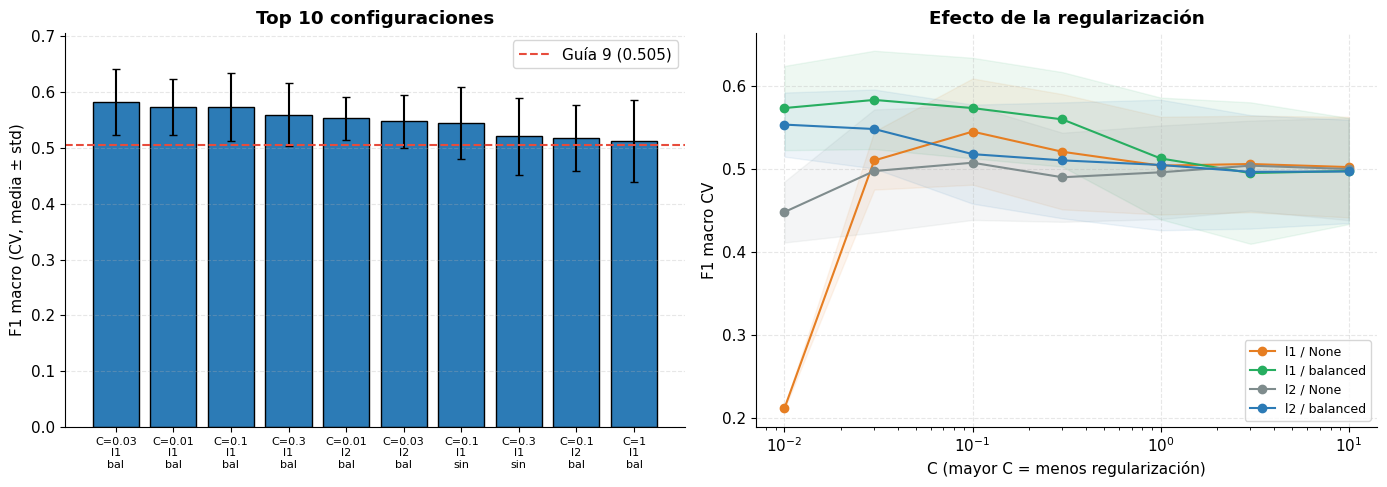

Promedio por valor de C (sobre penalizaciones y class_weight):


,F1_cv,F1_train,Brecha_F1
C,,,
0.01,0.447,0.490,0.043
0.03,0.535,0.590,0.056
0.10,0.536,0.608,0.072
0.30,0.520,0.636,0.115
1.00,0.504,0.663,0.159
3.00,0.500,0.671,0.171
10.00,0.499,0.673,0.174


In [34]:
# ============================================================
# CELDA 10: Gráficos de la búsqueda
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Top 10 con barras de error
top = tabla.head(10)
etiquetas = [f"C={r.C:g}\n{r.penalty}\n{'bal' if r.class_weight=='balanced' else 'sin'}" for r in top.itertuples()]
axes[0].bar(range(len(top)), top["F1_cv"], yerr=top["F1_std"], capsize=3,
            color="#2c7bb6", edgecolor="black")
axes[0].set_xticks(range(len(top))); axes[0].set_xticklabels(etiquetas, fontsize=8)
axes[0].axhline(fila_g9["F1_cv"], color="#e74c3c", linestyle="--", label=f"Guía 9 ({fila_g9['F1_cv']:.3f})")
axes[0].set_ylabel("F1 macro (CV, media ± std)")
axes[0].set_title("Top 10 configuraciones", fontweight="bold")
axes[0].set_ylim(0, max(0.7, top["F1_cv"].max() + top["F1_std"].max() + 0.05))
axes[0].legend(); axes[0].grid(alpha=0.3, axis="y", linestyle="--")

# (b) Efecto de C por penalización y class_weight (Ejercicio 2 análogo: complejidad vs. sobreajuste)
colores = {("l2", "None"): "#7f8c8d", ("l2", "balanced"): "#2c7bb6",
           ("l1", "None"): "#e67e22", ("l1", "balanced"): "#27ae60"}
for (pen, cw), g in tabla.groupby(["penalty", "class_weight"]):
    g = g.sort_values("C")
    axes[1].plot(g["C"], g["F1_cv"], marker="o", color=colores[(pen, cw)], label=f"{pen} / {cw}")
    axes[1].fill_between(g["C"], g["F1_cv"] - g["F1_std"], g["F1_cv"] + g["F1_std"],
                         color=colores[(pen, cw)], alpha=0.08)
axes[1].set_xscale("log"); axes[1].set_xlabel("C (mayor C = menos regularización)")
axes[1].set_ylabel("F1 macro CV"); axes[1].set_title("Efecto de la regularización", fontweight="bold")
axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3, linestyle="--")

plt.tight_layout()
fig.savefig(DIR_EVID / "grafico_gridsearch_top10_y_C.png", dpi=150)
plt.show()

# Brecha vs. C: ¿más complejidad = más sobreajuste?
g = tabla.groupby("C")[["F1_cv", "F1_train", "Brecha_F1"]].mean().round(3)
print("Promedio por valor de C (sobre penalizaciones y class_weight):")
display(g)

## Parte E — Selección con la regla declarada
Se aplica la regla de un error estándar fijada al inicio del notebook. La mejor media no se elige automáticamente: se prefiere la configuración más regularizada cuya diferencia con la mejor no es distinguible del ruido entre folds.

In [35]:
# ============================================================
# CELDA 11: Regla de un error estándar y modelo final
# ============================================================
mejor = tabla.iloc[0]                                  # mejor media de F1 CV
umbral_1se = mejor["F1_cv"] - mejor["SE"]
dentro = tabla[tabla["F1_cv"] >= umbral_1se]
parsimonioso = dentro.sort_values(["C", "F1_cv"], ascending=[True, False]).iloc[0]

print("SELECCIÓN")
print("=" * 70)
print(f"Mejor por media:      C={mejor['C']:g}, {mejor['penalty']}, {mejor['class_weight']}  "
      f"-> F1 CV {mejor['F1_cv']:.3f} ± {mejor['F1_std']:.3f}  (SE {mejor['SE']:.3f})")
print(f"Umbral (mejor - 1 SE): {umbral_1se:.3f}  | configuraciones dentro del umbral: {len(dentro)} de {n_comb}")
print(f"Elegida (más simple): C={parsimonioso['C']:g}, {parsimonioso['penalty']}, {parsimonioso['class_weight']}  "
      f"-> F1 CV {parsimonioso['F1_cv']:.3f} ± {parsimonioso['F1_std']:.3f}")

params_final = parsimonioso["params"]
modelo_final = clone(busqueda.estimator).set_params(**params_final)
t0 = time.perf_counter()
modelo_final.fit(X_train, y_train)                     # refit sobre TODO X_train
t_fit_final = time.perf_counter() - t0

n_it = int(np.max(modelo_final.named_steps["clf"].n_iter_))
print(f"\nModelo final reajustado sobre {len(X_train)} filas en {t_fit_final:.2f} s "
      f"({n_it} iteraciones; {'convergió' if n_it < 5000 else 'AVISO: sin convergencia'})")

if params_final["clf__penalty"] == "l1":
    coef = modelo_final.named_steps["clf"].coef_
    print(f"Coeficientes distintos de cero (l1): {int((np.abs(coef).sum(axis=0) > 0).sum())} de {coef.shape[1]} columnas transformadas")

SELECCIÓN
Mejor por media:      C=0.03, l1, balanced  -> F1 CV 0.583 ± 0.059  (SE 0.026)
Umbral (mejor - 1 SE): 0.557  | configuraciones dentro del umbral: 4 de 28
Elegida (más simple): C=0.01, l1, balanced  -> F1 CV 0.573 ± 0.051

Modelo final reajustado sobre 700 filas en 0.45 s (221 iteraciones; convergió)
Coeficientes distintos de cero (l1): 2 de 90 columnas transformadas


In [36]:
# ============================================================
# CELDA 12: Validación cruzada anidada (estimación menos optimista)
# ============================================================
# El puntaje del mejor candidato de un grid está sesgado hacia arriba porque se eligió
# mirando esos mismos folds. En la CV anidada la búsqueda completa se repite dentro de
# cada fold externo, de modo que cada fold externo es "datos nunca vistos por la búsqueda".
if RUN_NESTED:
    cv_ext = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE + 1)
    cv_int = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE + 2)
    busq_interna = GridSearchCV(crear_pipeline(max_iter=5000), param_grid,
                                scoring="f1_macro", cv=cv_int, n_jobs=1)
    t0 = time.perf_counter()
    nested_opt  = cross_val_score(busq_interna, X_train, y_train, cv=cv_ext, scoring="f1_macro", n_jobs=-1)
    nested_base = cross_val_score(crear_config_g9(), X_train, y_train, cv=cv_ext, scoring="f1_macro", n_jobs=-1)
    t_nested = time.perf_counter() - t0
    dif = nested_opt - nested_base
    print("VALIDACIÓN CRUZADA ANIDADA (folds externos, mismos para ambos)")
    print("=" * 70)
    print(f"Guía 9 (config fija):          F1 macro {nested_base.mean():.3f} ± {nested_base.std(ddof=1):.3f}")
    print(f"Búsqueda completa (grid):      F1 macro {nested_opt.mean():.3f} ± {nested_opt.std(ddof=1):.3f}")
    print(f"Diferencia pareada por fold:   {np.round(dif, 3)}  | media {dif.mean():+.3f}")
    print(f"Folds donde la búsqueda gana:  {int((dif > 0).sum())} de {N_FOLDS}  | tiempo: {t_nested:.0f} s")
    NESTED = {"base_mean": nested_base.mean(), "opt_mean": nested_opt.mean(), "dif_mean": dif.mean(),
              "folds_ganados": int((dif > 0).sum())}
else:
    NESTED = None
    print("CV anidada omitida (RUN_NESTED = False).")

VALIDACIÓN CRUZADA ANIDADA (folds externos, mismos para ambos)
Guía 9 (config fija):          F1 macro 0.522 ± 0.024
Búsqueda completa (grid):      F1 macro 0.581 ± 0.039
Diferencia pareada por fold:   [ 0.043  0.096 -0.003  0.071  0.089]  | media +0.059
Folds donde la búsqueda gana:  4 de 5  | tiempo: 579 s


## Parte F — Decisión previa a la prueba final
La decisión de adoptar o no la configuración optimizada se toma **solo con validación cruzada**, aplicando las reglas declaradas al inicio. La validación (15 %) no participó en la búsqueda y sirve como control adicional. La prueba final se abre después.

In [37]:
# ============================================================
# CELDA 13: Ajustar referencias, medir costo y controlar con validación
# ============================================================
def metricas(y_real, y_pred):
    y_real = np.asarray(y_real); y_pred = np.asarray(y_pred)
    return {
        "F1_macro": f1_score(y_real, y_pred, average="macro", zero_division=0),
        "Accuracy": accuracy_score(y_real, y_pred),
        "Prec_macro": precision_score(y_real, y_pred, average="macro", zero_division=0),
        "Rec_macro": recall_score(y_real, y_pred, average="macro", zero_division=0),
        "Recall_Alto": recall_alto(y_real, y_pred),
        "MAE_ordinal": mae_ordinal(y_real, y_pred),
        "Criticos_Alto_a_Bajo": int(((y_real == "Alto") & (y_pred == "Bajo")).sum()),
    }

NOM_BASE, NOM_G9, NOM_G10 = "Baseline", "Candidato Guía 9", "Optimizado Guía 10"
modelos_fit, tiempos_fit = {}, {}
for nombre, est in [(NOM_BASE, DummyClassifier(strategy="most_frequent")), (NOM_G9, crear_config_g9())]:
    m = clone(est); t0 = time.perf_counter(); m.fit(X_train, y_train)
    tiempos_fit[nombre] = time.perf_counter() - t0; modelos_fit[nombre] = m
modelos_fit[NOM_G10] = modelo_final
tiempos_fit[NOM_G10] = t_fit_final

val_rows = []
for nombre, m in modelos_fit.items():
    val_rows.append({"Modelo": nombre, **metricas(y_val, m.predict(X_val))})
tabla_val = pd.DataFrame(val_rows).set_index("Modelo")
print("CONTROL EN VALIDACIÓN (no participó en GridSearchCV)")
print("=" * 90)
display(tabla_val.round(3))

CONTROL EN VALIDACIÓN (no participó en GridSearchCV)


,F1_macro,Accuracy,Prec_macro,Rec_macro,Recall_Alto,MAE_ordinal,Criticos_Alto_a_Bajo
Modelo,,,,,,,
Baseline,0.212,0.467,0.156,0.333,1.000,0.747,0
Candidato Guía 9,0.529,0.540,0.535,0.544,0.529,0.607,16
Optimizado Guía 10,0.564,0.567,0.640,0.607,0.414,0.560,19


In [38]:
# ============================================================
# CELDA 14: Aplicar las reglas de adopción declaradas al inicio
# ============================================================
f1_cv_base_cfg = fila_g9["F1_cv"]
f1_cv_final = parsimonioso["F1_cv"]
delta_cv = f1_cv_final - f1_cv_base_cfg
caida_recall = fila_g9["RecallAlto_cv"] - parsimonioso["RecallAlto_cv"]
aumento_std = (parsimonioso["F1_std"] - fila_g9["F1_std"]) / fila_g9["F1_std"]

reglas = [
    (f"(a) Mejora de F1 CV >= {UMBRAL_MEJORA_F1_CV}", delta_cv >= UMBRAL_MEJORA_F1_CV,
     f"{f1_cv_base_cfg:.3f} -> {f1_cv_final:.3f} ({delta_cv:+.3f})"),
    (f"(b) Recall Alto CV no cae más de {MAX_CAIDA_RECALL_ALTO}", caida_recall <= MAX_CAIDA_RECALL_ALTO,
     f"{fila_g9['RecallAlto_cv']:.3f} -> {parsimonioso['RecallAlto_cv']:.3f} (caída {caida_recall:+.3f})"),
    (f"(c) std entre folds no aumenta más de {MAX_AUMENTO_STD:.0%}", aumento_std <= MAX_AUMENTO_STD,
     f"{fila_g9['F1_std']:.3f} -> {parsimonioso['F1_std']:.3f} ({aumento_std:+.0%})"),
]
print("REGLAS DE ADOPCIÓN (declaradas antes de la búsqueda)")
print("=" * 90)
for txt, ok, det in reglas:
    print(f"  [{'CUMPLE' if ok else 'NO CUMPLE'}] {txt}: {det}")

ADOPTAR = all(ok for _, ok, _ in reglas)
mismo_modelo = (params_final.get("clf__C") == 1 and params_final.get("clf__penalty") == "l2"
                and params_final.get("clf__class_weight") == "balanced")
if ADOPTAR:
    DECISION = "ADOPTAR la configuración optimizada"
elif mismo_modelo:
    DECISION = "CONSERVAR la configuración de la Guía 9 (la búsqueda confirma que ya era la elegida)"
else:
    DECISION = "CONSERVAR la configuración de la Guía 9 (el F1 CV mejora, pero no se cumplen todas las reglas de adopción)"
print(f"\nDECISIÓN: {DECISION}")

REGLAS DE ADOPCIÓN (declaradas antes de la búsqueda)
  [CUMPLE] (a) Mejora de F1 CV >= 0.01: 0.505 -> 0.573 (+0.068)
  [NO CUMPLE] (b) Recall Alto CV no cae más de 0.03: 0.532 -> 0.453 (caída +0.079)
  [CUMPLE] (c) std entre folds no aumenta más de 25%: 0.088 -> 0.051 (-42%)

DECISIÓN: CONSERVAR la configuración de la Guía 9 (el F1 CV mejora, pero no se cumplen todas las reglas de adopción)


## Parte G — Evaluación final en el holdout (una sola vez)
Se cierra la selección. La función siguiente **impide** una segunda lectura del conjunto de prueba: si se vuelve a ejecutar la celda, lanza un error. Así queda demostrado que la prueba no influyó en el ajuste.

In [39]:
# ============================================================
# CELDA 15: Evaluación final en prueba (única) y comparación antes/después
# ============================================================
TEST_USADO = False
def evaluar_en_test(modelos_dict):
    """Predice sobre X_test. Solo puede ejecutarse una vez por sesión."""
    global TEST_USADO
    if TEST_USADO:
        raise RuntimeError("El conjunto de prueba ya fue usado. Repetir la evaluación lo convertiría en validación.")
    TEST_USADO = True
    return {n: m.predict(X_test) for n, m in modelos_dict.items()}

preds_test = evaluar_en_test(modelos_fit)

filas = []
f1_base_test = metricas(y_test, preds_test[NOM_BASE])["F1_macro"]
m_g9_test = metricas(y_test, preds_test[NOM_G9])
for nombre in [NOM_BASE, NOM_G9, NOM_G10]:
    mt = metricas(y_test, preds_test[nombre])
    cv_ref = df_ref.loc[nombre] if nombre in df_ref.index else None
    if nombre == NOM_G10:
        f1_cv, f1_sd = parsimonioso["F1_cv"], parsimonioso["F1_std"]
    elif nombre == NOM_G9:
        f1_cv, f1_sd = fila_g9["F1_cv"], fila_g9["F1_std"]
    else:
        f1_cv, f1_sd = fila_base["F1_cv"], fila_base["F1_std"]
    filas.append({
        "Modelo": nombre,
        "F1_cv": f1_cv, "F1_cv_std": f1_sd, "F1_val": tabla_val.loc[nombre, "F1_macro"],
        "F1_test": mt["F1_macro"], "Acc_test": mt["Accuracy"],
        "Recall_Alto_test": mt["Recall_Alto"], "MAE_ordinal_test": mt["MAE_ordinal"],
        "Criticos_Alto_a_Bajo": mt["Criticos_Alto_a_Bajo"],
        "Tiempo_fit_s": tiempos_fit[nombre],
        "Mejora_F1_vs_baseline_pct": (mt["F1_macro"] - f1_base_test) / f1_base_test * 100,
        "Mejora_F1_vs_G9_pts": mt["F1_macro"] - m_g9_test["F1_macro"],
    })
comparacion = pd.DataFrame(filas)
comparacion["Decision"] = ["Referencia mínima", "Configuración previa", DECISION]

print("COMPARACIÓN ANTES / DESPUÉS (mismo holdout de la Guía 9)")
print("=" * 110)
display(comparacion.round(3))

# Continuidad con la Guía 9 sobre el mismo holdout
ok_cont_test = abs(m_g9_test["F1_macro"] - G9_F1_TEST) < 5e-4 and abs(m_g9_test["Accuracy"] - G9_ACC_TEST) < 5e-4
print(f"\nContinuidad en prueba (Guía 9: F1 {G9_F1_TEST}, accuracy {G9_ACC_TEST}): "
      f"{'VERIFICADA' if ok_cont_test else 'AVISO: no coincide con la Guía 9'}")

COMPARACIÓN ANTES / DESPUÉS (mismo holdout de la Guía 9)


,Modelo,F1_cv,F1_cv_std,F1_val,F1_test,Acc_test,Recall_Alto_test,MAE_ordinal_test,Criticos_Alto_a_Bajo,Tiempo_fit_s,Mejora_F1_vs_baseline_pct,Mejora_F1_vs_G9_pts,Decision
0,Baseline,0.212,0.001,0.212,0.212,0.467,1.000,0.740,0,0.002,0.000,-0.372,Referencia mínima
1,Candidato Guía 9,0.505,0.088,0.529,0.584,0.607,0.629,0.480,12,0.114,175.322,0.000,Configuración previa
2,Optimizado Guía 10,0.573,0.051,0.564,0.626,0.633,0.529,0.467,15,0.450,195.060,0.042,CONSERVAR la configuración de la Guía 9 (el F1...



Continuidad en prueba (Guía 9: F1 0.584, accuracy 0.6067): VERIFICADA


In [40]:
# ============================================================
# CELDA 16: Incertidumbre en prueba (bootstrap) — ¿la diferencia es real?
# ============================================================
# Con 150 registros la métrica de prueba tiene un margen de error amplio.
# Se remuestrean las predicciones ya hechas (no se vuelve a evaluar ningún modelo).
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.to_numpy(); pa = np.asarray(preds_test[NOM_G9]); pb = np.asarray(preds_test[NOM_G10])
pbase = np.asarray(preds_test[NOM_BASE])
n = len(yt)
f1_b, d_g9, d_base = [], [], []
for _ in range(N_BOOT):
    i = rng.integers(0, n, n)
    fb = f1_score(yt[i], pb[i], average="macro", zero_division=0)
    f1_b.append(fb)
    d_g9.append(fb - f1_score(yt[i], pa[i], average="macro", zero_division=0))
    d_base.append(fb - f1_score(yt[i], pbase[i], average="macro", zero_division=0))
ic = lambda v: np.percentile(v, [2.5, 97.5])
ic_f1, ic_g9, ic_base = ic(f1_b), ic(d_g9), ic(d_base)

print(f"BOOTSTRAP ({N_BOOT} remuestreos) sobre la prueba final")
print("=" * 70)
print(f"F1 macro optimizado:          {np.mean(f1_b):.3f}   IC 95 % [{ic_f1[0]:.3f}, {ic_f1[1]:.3f}]")
print(f"Diferencia vs Guía 9:         {np.mean(d_g9):+.3f}   IC 95 % [{ic_g9[0]:+.3f}, {ic_g9[1]:+.3f}]  "
      f"-> {'incluye 0: no distinguible' if ic_g9[0] <= 0 <= ic_g9[1] else 'no incluye 0'}")
print(f"Diferencia vs baseline:       {np.mean(d_base):+.3f}   IC 95 % [{ic_base[0]:+.3f}, {ic_base[1]:+.3f}]  "
      f"-> {'incluye 0: no distinguible' if ic_base[0] <= 0 <= ic_base[1] else 'no incluye 0: supera al baseline'}")

BOOTSTRAP (2000 remuestreos) sobre la prueba final
F1 macro optimizado:          0.625   IC 95 % [0.547, 0.701]
Diferencia vs Guía 9:         +0.042   IC 95 % [-0.026, +0.110]  -> incluye 0: no distinguible
Diferencia vs baseline:       +0.413   IC 95 % [+0.325, +0.500]  -> no incluye 0: supera al baseline


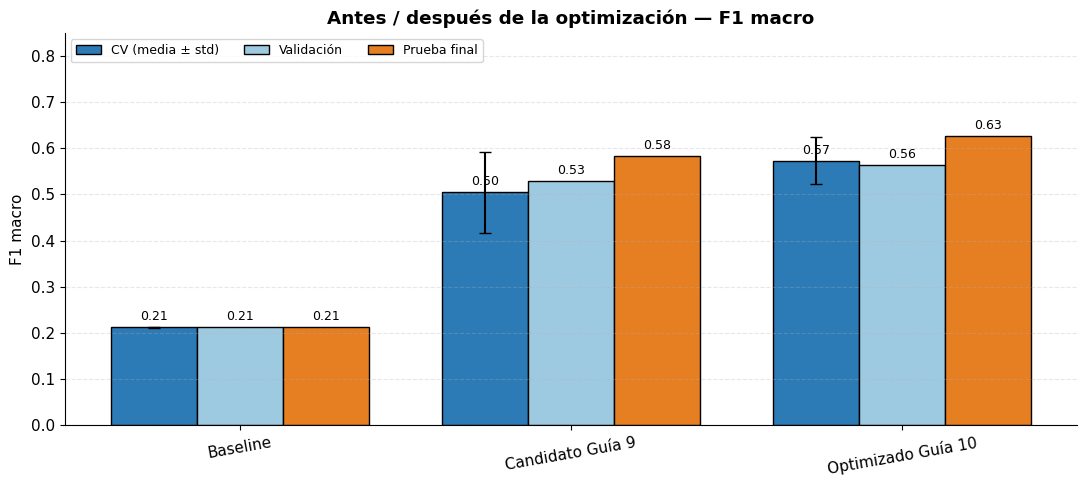

In [41]:
# ============================================================
# CELDA 17: Gráfico antes/después
# ============================================================
g = comparacion.set_index("Modelo")
x = np.arange(len(g)); w = 0.26
fig, ax = plt.subplots(figsize=(11, 5))
b1 = ax.bar(x - w, g["F1_cv"], w, yerr=g["F1_cv_std"], capsize=4, label="CV (media ± std)", color="#2c7bb6", edgecolor="black")
b2 = ax.bar(x, g["F1_val"], w, label="Validación", color="#9ecae1", edgecolor="black")
b3 = ax.bar(x + w, g["F1_test"], w, label="Prueba final", color="#e67e22", edgecolor="black")
for barras in (b1, b2, b3):
    for b in barras:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.015, f"{b.get_height():.2f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(g.index, rotation=10)
ax.set_ylabel("F1 macro"); ax.set_ylim(0, 0.85)
ax.set_title("Antes / después de la optimización — F1 macro", fontweight="bold")
ax.legend(ncol=3, loc="upper left", fontsize=9); ax.grid(alpha=0.3, axis="y", linestyle="--")
plt.tight_layout(); fig.savefig(DIR_EVID / "grafico_antes_despues.png", dpi=150); plt.show()

## Parte H — Errores del modelo optimizado
Se analizan los errores sin eliminar ningún registro por ser difícil de predecir.

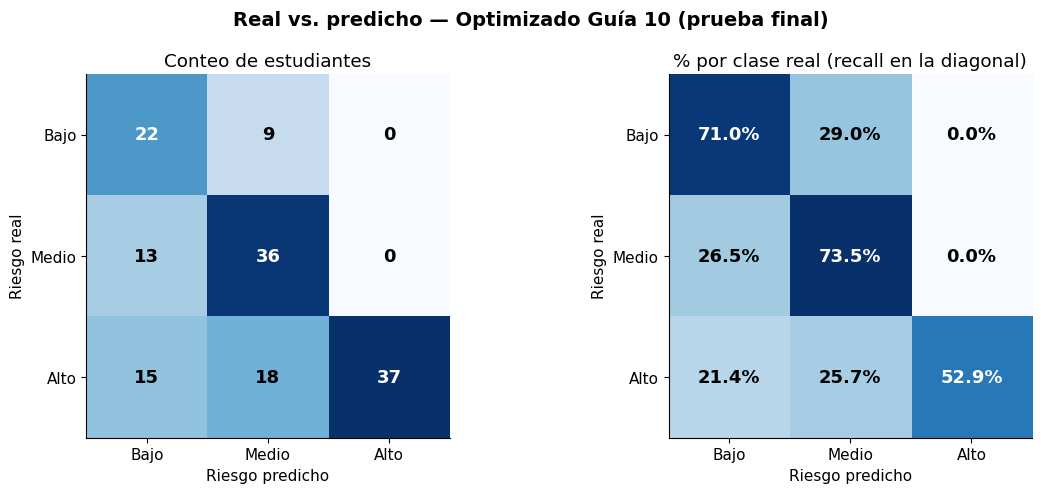

              precision    recall  f1-score   support

        Bajo      0.440     0.710     0.543        31
       Medio      0.571     0.735     0.643        49
        Alto      1.000     0.529     0.692        70

    accuracy                          0.633       150
   macro avg      0.670     0.658     0.626       150
weighted avg      0.744     0.633     0.645       150


Aciertos: 95/150 | errores a distancia 1: 40 | distancia 2: 15
Errores críticos (real Alto, predicho Bajo): optimizado 15 vs Guía 9 12

TOP 5 ERRORES MÁS GRAVES


,id_fila,real,predicho,distancia_ordinal,prob_predicho,prob_real
0,689,Alto,Bajo,2,0.478,0.233
1,522,Alto,Bajo,2,0.465,0.239
2,358,Alto,Bajo,2,0.460,0.242
3,972,Alto,Bajo,2,0.449,0.247
4,225,Alto,Bajo,2,0.432,0.254


,id_fila,materia,nota_final,porcentaje_asistencia,faltas_consecutivas,actividad_lms,materia_reprobada
0,689,Matematica I,9.66,90.0,1,3,0
1,522,Ingles,9.44,70.0,3,14,0
2,358,Base de Datos,9.35,100.0,0,6,0
3,972,Ingles,9.14,90.0,1,1,0
4,225,Base de Datos,8.86,60.0,4,5,0



Registros de prueba etiquetados 'Alto' con nota_final >= 9, asistencia >= 90 % y sin materia reprobada: 3
Si hay varios, parte del 'error' puede deberse a la definición de la etiqueta y no al modelo: revisar cómo se construye riesgo_academico antes de seguir optimizando.


In [42]:
# ============================================================
# CELDA 18: Matriz de confusión, errores graves y chequeo de etiquetas
# ============================================================
pred_final = np.asarray(preds_test[NOM_G10])
cm = confusion_matrix(y_test, pred_final, labels=ORDEN_CLASES)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, datos, titulo, fmt in [(axes[0], cm, "Conteo de estudiantes", "{:d}"),
                               (axes[1], cm_pct, "% por clase real (recall en la diagonal)", "{:.1f}%")]:
    ax.imshow(datos, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_xticklabels(ORDEN_CLASES)
    ax.set_yticks(range(3)); ax.set_yticklabels(ORDEN_CLASES)
    ax.set_xlabel("Riesgo predicho"); ax.set_ylabel("Riesgo real"); ax.set_title(titulo)
    for i in range(3):
        for j in range(3):
            v = datos[i, j]
            ax.text(j, i, fmt.format(int(v) if fmt == "{:d}" else v), ha="center", va="center",
                    fontsize=13, fontweight="bold", color="white" if v > datos.max() / 2 else "black")
plt.suptitle(f"Real vs. predicho — {NOM_G10} (prueba final)", fontsize=14, fontweight="bold")
plt.tight_layout(); fig.savefig(DIR_EVID / "grafico_confusion_optimizado.png", dpi=150); plt.show()
print(classification_report(y_test, pred_final, labels=ORDEN_CLASES, digits=3, zero_division=0))

# Tabla de predicciones con probabilidades
clases_modelo = list(modelo_final.classes_)
proba = modelo_final.predict_proba(X_test)
errores = pd.DataFrame({"id_fila": X_test.index, "real": y_test.values, "predicho": pred_final})
errores["acierto"] = (errores["real"] == errores["predicho"]).astype(int)
errores["distancia_ordinal"] = (errores["real"].map(MAPA_ORD) - errores["predicho"].map(MAPA_ORD)).abs()
for k, c in enumerate(clases_modelo):
    errores[f"prob_{c}"] = proba[:, k]
errores["prob_predicho"] = errores[[f"prob_{c}" for c in clases_modelo]].max(axis=1)
errores["prob_real"] = [errores.loc[i, f"prob_{r}"] for i, r in zip(errores.index, errores["real"])]

crit10 = int(((errores["real"] == "Alto") & (errores["predicho"] == "Bajo")).sum())
crit_g9 = int(m_g9_test["Criticos_Alto_a_Bajo"])
print(f"\nAciertos: {int(errores['acierto'].sum())}/{len(errores)} | errores a distancia 1: {int((errores['distancia_ordinal']==1).sum())} "
      f"| distancia 2: {int((errores['distancia_ordinal']==2).sum())}")
print(f"Errores críticos (real Alto, predicho Bajo): optimizado {crit10} vs Guía 9 {crit_g9}")

top5 = (errores[errores["acierto"] == 0]
        .sort_values(["distancia_ordinal", "prob_predicho"], ascending=False).head(5)
        [["id_fila", "real", "predicho", "distancia_ordinal", "prob_predicho", "prob_real"]].reset_index(drop=True))
print("\nTOP 5 ERRORES MÁS GRAVES")
display(top5.round(3))
perfil = df.loc[top5["id_fila"], ["materia", "nota_final", "porcentaje_asistencia", "faltas_consecutivas",
                                  "actividad_lms", "materia_reprobada"]].reset_index().rename(columns={"index": "id_fila"})
display(perfil)

# Chequeo de coherencia de etiquetas: perfiles aparentemente seguros etiquetados como Alto
dt = df.loc[X_test.index]
seguros_alto = dt[(dt["riesgo_academico"] == "Alto") & (dt["nota_final"] >= 9)
                  & (dt["materia_reprobada"] == 0) & (dt["porcentaje_asistencia"] >= 90)]
print(f"\nRegistros de prueba etiquetados 'Alto' con nota_final >= 9, asistencia >= 90 % y sin materia reprobada: {len(seguros_alto)}")
print("Si hay varios, parte del 'error' puede deberse a la definición de la etiqueta y no al modelo: "
      "revisar cómo se construye riesgo_academico antes de seguir optimizando.")

IMPORTANCIA POR PERMUTACIÓN (caída de F1 macro en validación al barajar la variable)


,variable,caida_F1_media,std
0,materia_reprobada,0.1692,0.0239
1,promedio_academico,0.0966,0.0299
2,ciclo_actual,0.0000,0.0000
3,anio_ingreso,0.0000,0.0000
4,edad,0.0000,0.0000
5,tareas_entregadas,0.0000,0.0000
6,tareas_tarde,0.0000,0.0000
7,porcentaje_asistencia,0.0000,0.0000
8,actividad_lms,0.0000,0.0000
9,total_observaciones,0.0000,0.0000


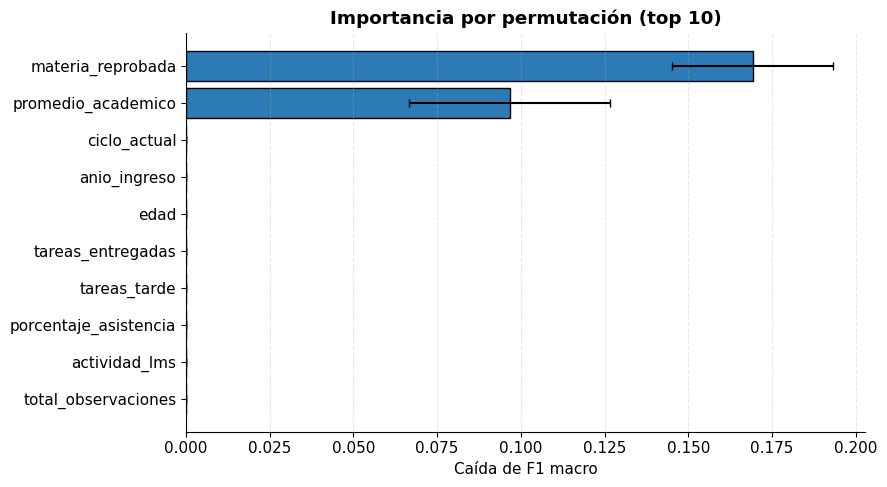

Variables de desempeño entre las 5 principales: ['materia_reprobada', 'promedio_academico']
Recordatorio: importancia predictiva no es causalidad, y nota_final / promedio_academico / materia_reprobada están correlacionadas: al barajar una, las otras compensan y su importancia se subestima.


In [43]:
# ============================================================
# CELDA 19: Importancia por permutación (sobre validación, variable original)
# ============================================================
# Corrige el sesgo de sumar |coeficientes| one-hot (favorece variables con muchos niveles):
# aquí se mide cuánto cae el F1 al barajar cada variable ORIGINAL, usando el pipeline completo.
perm = permutation_importance(modelo_final, X_val, y_val, scoring="f1_macro",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
tabla_imp = (pd.DataFrame({"variable": X_val.columns, "caida_F1_media": perm.importances_mean,
                           "std": perm.importances_std})
             .sort_values("caida_F1_media", ascending=False).reset_index(drop=True))
print("IMPORTANCIA POR PERMUTACIÓN (caída de F1 macro en validación al barajar la variable)")
print("=" * 80)
display(tabla_imp.head(12).round(4))

top = tabla_imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top["variable"], top["caida_F1_media"], xerr=top["std"], color="#2c7bb6", edgecolor="black", capsize=3)
ax.set_xlabel("Caída de F1 macro"); ax.set_title("Importancia por permutación (top 10)", fontweight="bold")
ax.grid(alpha=0.3, axis="x", linestyle="--"); plt.tight_layout()
fig.savefig(DIR_EVID / "grafico_importancia_permutacion.png", dpi=150); plt.show()

notas_top5 = [v for v in tabla_imp.head(5)["variable"] if v in features_notas]
print(f"Variables de desempeño entre las 5 principales: {notas_top5 if notas_top5 else 'ninguna'}")
print("Recordatorio: importancia predictiva no es causalidad, y nota_final / promedio_academico / "
      "materia_reprobada están correlacionadas: al barajar una, las otras compensan y su importancia se subestima.")

## Parte I — Ejercicios complementarios (costo del grid y número de folds)
Cubren los ejercicios 1 y 3 de la guía sin tocar la prueba final. El ejercicio 2 (efecto de la complejidad) se ve en el gráfico de `C` y el ejercicio 4 (métrica alternativa) en la correlación de Spearman de la celda 9.

In [44]:
# ============================================================
# CELDA 20: Grid compacto vs. completo y 3 vs. 5 folds
# ============================================================
def correr_grid(nombre, pg, k):
    cv_k = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)
    g = GridSearchCV(crear_pipeline(max_iter=5000), pg, scoring="f1_macro", cv=cv_k, n_jobs=-1)
    t0 = time.perf_counter(); g.fit(X_train, y_train); t = time.perf_counter() - t0
    i = g.best_index_
    return {"Experimento": nombre, "Combinaciones": len(ParameterGrid(pg)), "Folds": k,
            "Entrenamientos": len(ParameterGrid(pg)) * k,
            "Mejores parámetros": str({kk.replace("clf__", ""): v for kk, v in g.best_params_.items()}),
            "F1_cv": g.cv_results_["mean_test_score"][i], "F1_std": g.cv_results_["std_test_score"][i],
            "Tiempo_s": t}

grid_compacto = [{"clf__solver": ["lbfgs"], "clf__penalty": ["l2"], "clf__C": [0.1, 1, 10], "clf__class_weight": CLASS_WEIGHT}]
ej = [
    {"Experimento": "Grid completo, 5 folds (principal)", "Combinaciones": n_comb, "Folds": N_FOLDS,
     "Entrenamientos": n_comb * N_FOLDS,
     "Mejores parámetros": str({k.replace("clf__", ""): v for k, v in busqueda.best_params_.items()}),
     "F1_cv": busqueda.best_score_, "F1_std": mejor["F1_std"], "Tiempo_s": tiempo_busqueda},
    correr_grid("Grid compacto (solo l2), 5 folds", grid_compacto, 5),
    correr_grid("Grid completo, 3 folds", param_grid, 3),
]
tabla_ej = pd.DataFrame(ej)
display(tabla_ej.round(3))
dif_t = tabla_ej.loc[0, "Tiempo_s"] / max(tabla_ej.loc[1, "Tiempo_s"], 1e-9)
dif_f = tabla_ej.loc[0, "F1_cv"] - tabla_ej.loc[1, "F1_cv"]
sd_ref = tabla_ej.loc[0, "F1_std"]
print(f"El grid completo tarda {dif_t:.1f}x más que el compacto y cambia el F1 CV en {dif_f:+.3f} "
      f"({'menos' if abs(dif_f) < sd_ref else 'más'} que la std entre folds, {sd_ref:.3f}): "
      f"{'el costo adicional no se justifica por sí solo' if abs(dif_f) < sd_ref else 'la ampliación aporta una diferencia mayor al ruido'}.")

,Experimento,Combinaciones,Folds,Entrenamientos,Mejores parámetros,F1_cv,F1_std,Tiempo_s
0,"Grid completo, 5 folds (principal)",28,5,140,"{'C': 0.03, 'class_weight': 'balanced', 'penal...",0.583,0.059,155.327
1,"Grid compacto (solo l2), 5 folds",6,5,30,"{'C': 0.1, 'class_weight': 'balanced', 'penalt...",0.518,0.060,1.624
2,"Grid completo, 3 folds",28,3,84,"{'C': 0.1, 'class_weight': 'balanced', 'penalt...",0.579,0.031,59.253


El grid completo tarda 95.7x más que el compacto y cambia el F1 CV en +0.065 (más que la std entre folds, 0.059): la ampliación aporta una diferencia mayor al ruido.


## Parte J — Artefactos reproducibles
Se exportan el registro completo de `GridSearchCV`, la comparación antes/después, las predicciones, el pipeline completo (preprocesamiento + modelo) y una bitácora con versiones, huellas y parámetros.

> **Seguridad:** los archivos `joblib`/`pickle` pueden ejecutar código al cargarse. Cargar solo artefactos generados por el propio equipo.

In [45]:
# ============================================================
# CELDA 21: Exportar resultados, modelo y bitácora
# ============================================================
ruta_grid   = DIR_DOCS / "gridsearch_resultados_guia10.csv"
ruta_comp   = DIR_DOCS / "comparacion_antes_despues_guia10.csv"
ruta_pred   = DIR_DATOS / "predicciones_modelo_optimizado_guia10.csv"
ruta_modelo = DIR_MODELOS / "modelo_optimizado_guia10.joblib"
ruta_bit    = DIR_DOCS / "bitacora_guia10.csv"
ruta_reg    = DIR_DOCS / "registro_busqueda_guia10.json"

res_export = res.copy()
res_export["params"] = res_export["params"].astype(str)
res_export.to_csv(ruta_grid, index=False, encoding="utf-8")
comparacion.to_csv(ruta_comp, index=False, encoding="utf-8")
errores.to_csv(ruta_pred, index=False, encoding="utf-8")
joblib.dump(modelo_final, ruta_modelo)           # pipeline completo, no solo el estimador

# Verificación: el modelo guardado reproduce las predicciones (sobre validación, no sobre prueba)
recargado = joblib.load(ruta_modelo)
assert isinstance(recargado, Pipeline)
assert (recargado.predict(X_val) == modelo_final.predict(X_val)).all()

registro = {
    "fecha_ejecucion": FECHA_EJEC,
    "versiones": {"python": platform.python_version(), "numpy": np.__version__,
                  "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
    "semilla": RANDOM_STATE,
    "dataset": {"archivo": NOMBRE_DATASET, "sha256_12": SHA_DATASET, "coincide_guia9": bool(MISMO_DATASET)},
    "holdout": {"huella_test": HUELLA_TEST, "coincide_guia9": bool(MISMO_TEST), "n_test": int(len(X_test))},
    "validacion": f"StratifiedKFold({N_FOLDS}, shuffle=True, random_state={RANDOM_STATE}) sobre X_train",
    "metrica_principal": "f1_macro",
    "grid": str(param_grid), "n_combinaciones": int(n_comb), "entrenamientos": int(n_comb * N_FOLDS),
    "tiempo_busqueda_s": round(float(tiempo_busqueda), 2),
    "mejor_por_media": {k: (None if v is None else v) for k, v in busqueda.best_params_.items()},
    "configuracion_elegida_1se": params_final,
    "f1_cv_guia9": round(float(f1_cv_base_cfg), 4), "f1_cv_elegida": round(float(f1_cv_final), 4),
    "f1_test_guia9": round(float(m_g9_test["F1_macro"]), 4),
    "f1_test_optimizado": round(float(comparacion.loc[comparacion["Modelo"] == NOM_G10, "F1_test"].iloc[0]), 4),
    "ic95_dif_f1_vs_guia9": [round(float(ic_g9[0]), 4), round(float(ic_g9[1]), 4)],
    "cv_anidada": None if NESTED is None else {k: round(float(v), 4) for k, v in NESTED.items()},
    "decision": DECISION,
}
with open(ruta_reg, "w", encoding="utf-8") as fh:
    json.dump(registro, fh, ensure_ascii=False, indent=2, default=str)

bitacora = pd.DataFrame([{
    "Fecha": FECHA_EJEC[:10],
    "Experimento": "GridSearchCV regresión logística (C, penalización, class_weight)",
    "Cambio": f"{n_comb} combinaciones x {N_FOLDS} folds; regla de 1 error estándar",
    "Resultado": f"F1 CV {f1_cv_base_cfg:.3f} -> {f1_cv_final:.3f}; F1 prueba {m_g9_test['F1_macro']:.3f} -> "
                 f"{comparacion.loc[comparacion['Modelo'] == NOM_G10, 'F1_test'].iloc[0]:.3f}",
    "Decisión": DECISION,
    "Responsable": "Isela Alexandra Quintanilla Cruz",
}])
bitacora.to_csv(ruta_bit, index=False, encoding="utf-8")

print("ARTEFACTOS EXPORTADOS")
print("=" * 70)
for r in [ruta_grid, ruta_comp, ruta_pred, ruta_modelo, ruta_bit, ruta_reg]:
    print(f"  {r.relative_to(ROOT)}")
for g_ in sorted(DIR_EVID.glob("*.png")):
    print(f"  {g_.relative_to(ROOT)}")
print("\nModelo recargado: predicciones idénticas a las originales (verificado en validación).")

ARTEFACTOS EXPORTADOS
  documentos/gridsearch_resultados_guia10.csv
  documentos/comparacion_antes_despues_guia10.csv
  datos/procesados/predicciones_modelo_optimizado_guia10.csv
  modelos/modelo_optimizado_guia10.joblib
  documentos/bitacora_guia10.csv
  documentos/registro_busqueda_guia10.json
  evidencias/guia10_optimizacion/grafico_antes_despues.png
  evidencias/guia10_optimizacion/grafico_confusion_optimizado.png
  evidencias/guia10_optimizacion/grafico_gridsearch_top10_y_C.png
  evidencias/guia10_optimizacion/grafico_importancia_permutacion.png

Modelo recargado: predicciones idénticas a las originales (verificado en validación).


In [46]:
# ============================================================
# CELDA 22: Justificación técnica (se redacta según los resultados reales)
# ============================================================
cfg = (f"C={params_final['clf__C']:g}, penalización {params_final['clf__penalty']}, "
       f"class_weight={params_final['clf__class_weight']}")
f1t = comparacion.set_index("Modelo")
fallos = [f"{txt}: {det}" for txt, ok, det in reglas if not ok]

p1 = (f"Se evaluaron {n_comb} configuraciones de regresión logística ({n_comb * N_FOLDS} entrenamientos) con validación "
      f"cruzada estratificada de {N_FOLDS} folds solo sobre entrenamiento. La regla de un error estándar eligió {cfg}, con F1 macro CV "
      f"{f1_cv_final:.3f} ± {parsimonioso['F1_std']:.3f}, frente a {f1_cv_base_cfg:.3f} ± {fila_g9['F1_std']:.3f} de la configuración de la "
      f"Guía 9 ({delta_cv:+.3f}). El rango de F1 CV entre las {n_comb} configuraciones fue {rango:.3f} (std típica entre folds: "
      f"{tabla['F1_std'].median():.3f}): "
      + ("la búsqueda separa poco unas configuraciones de otras." if rango <= 2 * tabla['F1_std'].median()
         else "la elección de hiperparámetros sí pesa más que el ruido entre folds."))

if ADOPTAR:
    p2 = "La configuración cumple las tres reglas declaradas de antemano, por lo que se adopta como modelo optimizado."
else:
    p2 = (f"No cumple {len(fallos)} de las 3 reglas declaradas de antemano: {'; '.join(fallos)}. Por eso se conserva la configuración "
          "de la Guía 9: el F1 CV mejora, pero a costa de detectar menos estudiantes de riesgo Alto.")

if NESTED is not None:
    p2 += (f" La validación cruzada anidada, que estima el efecto de buscar sin sesgo de selección, dio {NESTED['opt_mean']:.3f} con búsqueda "
           f"frente a {NESTED['base_mean']:.3f} con la configuración fija ({NESTED['dif_mean']:+.3f}; la búsqueda gana en {NESTED['folds_ganados']} de {N_FOLDS} folds).")

p3 = (f"En la prueba final, evaluada una sola vez, el modelo optimizado obtuvo F1 macro {f1t.loc[NOM_G10, 'F1_test']:.3f} y accuracy "
      f"{f1t.loc[NOM_G10, 'Acc_test']:.3f}, frente a {f1t.loc[NOM_G9, 'F1_test']:.3f} de la Guía 9 y {f1t.loc[NOM_BASE, 'F1_test']:.3f} del baseline. "
      f"La diferencia contra la Guía 9 tiene IC 95 % [{ic_g9[0]:+.3f}, {ic_g9[1]:+.3f}], que "
      f"{'incluye' if ic_g9[0] <= 0 <= ic_g9[1] else 'no incluye'} el cero; el recall de Alto pasa de {f1t.loc[NOM_G9, 'Recall_Alto_test']:.3f} a {f1t.loc[NOM_G10, 'Recall_Alto_test']:.3f} y los errores críticos Alto→Bajo pasan de {crit_g9} a {crit10}.")

p4 = ("Con 150 registros de prueba, esta evidencia no permite afirmar mejoras finas. El modelo conserva las limitaciones heredadas: "
      "definición de la etiqueta por revisar (se deriva de las notas) y variables de desempeño correlacionadas; no hay estudiantes repetidos (1000 carnets únicos), por lo que no hace falta GroupKFold. "
      "Las importancias describen asociación, no causalidad.")

justificacion = "\n\n".join([p1, p2, p3, p4])
print("JUSTIFICACIÓN TÉCNICA")
print("=" * 70)
print(justificacion)
print(f"\n({len(justificacion.split())} palabras)")

JUSTIFICACIÓN TÉCNICA
Se evaluaron 28 configuraciones de regresión logística (140 entrenamientos) con validación cruzada estratificada de 5 folds solo sobre entrenamiento. La regla de un error estándar eligió C=0.01, penalización l1, class_weight=balanced, con F1 macro CV 0.573 ± 0.051, frente a 0.505 ± 0.088 de la configuración de la Guía 9 (+0.068). El rango de F1 CV entre las 28 configuraciones fue 0.371 (std típica entre folds: 0.060): la elección de hiperparámetros sí pesa más que el ruido entre folds.

No cumple 1 de las 3 reglas declaradas de antemano: (b) Recall Alto CV no cae más de 0.03: 0.532 -> 0.453 (caída +0.079). Por eso se conserva la configuración de la Guía 9: el F1 CV mejora, pero a costa de detectar menos estudiantes de riesgo Alto. La validación cruzada anidada, que estima el efecto de buscar sin sesgo de selección, dio 0.581 con búsqueda frente a 0.522 con la configuración fija (+0.059; la búsqueda gana en 4 de 5 folds).

En la prueba final, evaluada una sola vez,

## Parte K — Ejercicio 5: selección responsable

1. **¿Por qué `GridSearchCV` no debe recibir `X_test`?** Porque cada combinación se compara con los datos que recibe; si esos datos incluyen la prueba, la mejor configuración se elige *mirando* la prueba y su puntaje deja de ser una estimación independiente (fuga de información). La prueba debe quedar para una única evaluación final.
2. **Parámetro aprendido vs. hiperparámetro.** Los parámetros se aprenden en `fit()` (en la regresión logística, los coeficientes y el intercepto). Los hiperparámetros se fijan antes de entrenar y controlan cómo aprende (`C`, la penalización, `class_weight`).
3. **¿Qué representa `std_test_score`?** La desviación del puntaje entre los folds de validación: cuánto cambia el desempeño según los datos con los que se valide. Una media alta con std alta es menos confiable.
4. **¿Por qué un grid más grande no garantiza algo mejor?** Cada combinación adicional es otra oportunidad de que el azar de los folds la favorezca (sesgo de selección), cuesta tiempo y solo es "el mejor" dentro del espacio explorado. La celda 20 lo comprueba comparando el grid completo con uno compacto: si la diferencia de F1 es menor que la dispersión entre folds, el costo extra no se justifica.
5. **¿Qué problema resuelve `Pipeline`?** Asegura que la imputación, el escalado y el one-hot se ajusten solo con las filas de entrenamiento de cada fold y se apliquen a las de validación. Sin él, esas estadísticas se calcularían con todos los datos y se filtraría información.
6. **¿Cuándo `TimeSeriesSplit` es preferible a `KFold`?** Cuando el orden temporal importa (ventas diarias, sensores, logs): el modelo debe aprender del pasado y validar sobre el futuro. Aquí los registros son estudiante-materia sin eje temporal explícito, por eso se usa `StratifiedKFold`; si el dataset tuviera estudiantes repetidos correspondería `GroupKFold`.
7. **Mejora de 0.5 % que duplica el tiempo de entrenamiento.** Solo se justifica si el costo extra es irrelevante frente al valor de negocio (por ejemplo, un modelo que se reentrena una vez al ciclo) y la mejora supera el ruido entre folds. Si la mejora cae dentro de la desviación entre folds, se conserva la configuración más barata y simple: en este proyecto, la regla declarada de un error estándar aplica ese mismo criterio.

In [47]:
# ============================================================
# CELDA 23: Lista de cotejo (verificaciones calculadas, no asumidas)
# ============================================================
rec = joblib.load(ruta_modelo)
chk = [
    ("Se conserva la pregunta predictiva, el objetivo y las 29 variables", y.name == "riesgo_academico" and len(features) == 29),
    ("Dataset idéntico al de la Guía 9 (huella sha256)", MISMO_DATASET),
    ("Holdout idéntico al de la Guía 8/9 (huella verificada contra la constante de la Guía 9)", MISMO_TEST),
    ("Conjuntos disjuntos: train no comparte filas con val ni test",
     set(X_train.index).isdisjoint(X_test.index) and set(X_train.index).isdisjoint(X_val.index)),
    ("Referencia Guía 9 reproducida en CV (F1 0.505 ± 0.088)", cont_cv),
    ("Referencia Guía 9 reproducida en prueba (F1 0.584, accuracy 0.607)", ok_cont_test),
    ("Preprocesamiento dentro del Pipeline", isinstance(busqueda.estimator, Pipeline) and "prep" in busqueda.estimator.named_steps),
    ("Espacio de búsqueda incluye la configuración de la Guía 9 y el número de combinaciones coincide con cv_results_",
     bool(m_g9.any()) and n_comb == len(res)),
    ("Validación estratificada con los mismos folds de la Guía 9", isinstance(busqueda.cv, StratifiedKFold) and busqueda.n_splits_ == N_FOLDS),
    ("Métrica principal declarada y usada para el refit (F1 macro)", busqueda.refit == "f1_macro"),
    ("cv_results_ completo exportado", len(pd.read_csv(ruta_grid)) == n_comb),
    ("Se analizan media y dispersión entre folds", {"F1_cv", "F1_std"} <= set(tabla.columns)),
    ("Se revisa la brecha entrenamiento/validación", "Brecha_F1" in tabla.columns),
    ("Se registra el costo computacional (búsqueda y ajuste final)", tiempo_busqueda > 0 and "Tiempo_fit_s" in comparacion.columns),
    ("El mejor modelo convergió (iteraciones < max_iter)", n_it < 5000),
    ("La prueba final se usó una sola vez (control por código)", TEST_USADO is True),
    ("Comparación antes/después con las mismas reglas (3 modelos con F1 de prueba)",
     len(comparacion) == 3 and comparacion["F1_test"].notna().all()),
    ("Se analizan los cinco errores más graves", len(top5) == 5),
    ("Importancia por permutación calculada", not tabla_imp.empty),
    ("Pipeline completo guardado y recargable", ruta_modelo.exists() and isinstance(rec, Pipeline)),
    ("Bitácora y registro de la búsqueda exportados", ruta_bit.exists() and ruta_reg.exists()),
]
print("LISTA DE COTEJO")
print("=" * 90)
for i, (txt, ok) in enumerate(chk, 1):
    print(f"  {i:>2}. [{'CUMPLE' if ok else 'REVISAR'}] {txt}")
print(f"\nVerificaciones aprobadas: {sum(ok for _, ok in chk)} / {len(chk)}")
print("(Pendientes fuera del notebook: README, commit y reinicio completo del entorno para ejecutar desde cero.)")

LISTA DE COTEJO
   1. [CUMPLE] Se conserva la pregunta predictiva, el objetivo y las 29 variables
   2. [CUMPLE] Dataset idéntico al de la Guía 9 (huella sha256)
   3. [CUMPLE] Holdout idéntico al de la Guía 8/9 (huella verificada contra la constante de la Guía 9)
   4. [CUMPLE] Conjuntos disjuntos: train no comparte filas con val ni test
   5. [CUMPLE] Referencia Guía 9 reproducida en CV (F1 0.505 ± 0.088)
   6. [CUMPLE] Referencia Guía 9 reproducida en prueba (F1 0.584, accuracy 0.607)
   7. [CUMPLE] Preprocesamiento dentro del Pipeline
   8. [CUMPLE] Espacio de búsqueda incluye la configuración de la Guía 9 y el número de combinaciones coincide con cv_results_
   9. [CUMPLE] Validación estratificada con los mismos folds de la Guía 9
  10. [CUMPLE] Métrica principal declarada y usada para el refit (F1 macro)
  11. [CUMPLE] cv_results_ completo exportado
  12. [CUMPLE] Se analizan media y dispersión entre folds
  13. [CUMPLE] Se revisa la brecha entrenamiento/validación
  14. [CUMPLE]

In [48]:
# ============================================================
# CELDA 24: Descarga en Colab (solo si el entorno es Colab)
# ============================================================
if en_colab():
    import shutil
    from google.colab import files
    shutil.make_archive("/content/guia10_proyecto_final", "zip", ROOT)
    files.download("/content/guia10_proyecto_final.zip")
else:
    print("Entorno local: los archivos ya están en la estructura del proyecto.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusiones y continuidad

- **Qué se hizo:** se tomó el candidato de la Guía 9 (regresión logística), se definió un espacio de búsqueda pequeño y justificado, y se evaluó con los mismos folds y el mismo holdout. La decisión se rigió por reglas declaradas antes de ver resultados y por una validación cruzada anidada que corrige el optimismo del mejor puntaje del grid.
- **Cómo leer el resultado:** lo relevante no es la cifra más alta sino si la mejora supera el ruido entre folds (std ≈ 0.09 en la Guía 9) y el intervalo de confianza en prueba. Si no lo supera, la conclusión correcta es conservar la configuración más simple.
- **Qué falta antes de producción:** revisar la definición de `riesgo_academico` (casos con notas altas etiquetados como Alto), dejar documentado que no hay estudiantes repetidos (1000 carnets únicos, verificado en la celda 3), por lo que `GroupKFold` no es necesario, decidir si variables como `requiere_seguimiento` pueden ser consecuencia de la etiqueta, y definir monitoreo y actualización de datos.
- **Para la siguiente guía:** conservar `gridsearch_resultados_guia10.csv`, `comparacion_antes_despues_guia10.csv`, `predicciones_modelo_optimizado_guia10.csv`, `modelo_optimizado_guia10.joblib`, `bitacora_guia10.csv` y `registro_busqueda_guia10.json`.